<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# 01_01 Warm-up and first model

In this notebook you will:

* Recap the basics of NumPy: arrays, shapes, broadcasting, and vectorized operations.
* Practice Pandas for data handling: loading a dataset, inspecting it, selecting columns/rows, and computing simple statistics.
* Practice plotting with Matplotlib: simple scatter plots and histograms.

* Train your first machine learning model in this Master's: a k-Nearest Neighbors (kNN) classifier, using scikit-learn. You will also compare its performance with a simple baseline and understand the importance of preprocessing (scaling).

## The basics of NumPy

### 1) Creating arrays and dtypes  

NumPy’s core object is the **ndarray** (N-dimensional array).  
An array is:  

- **Homogeneous**: all elements have the same data type (`dtype`).  
- **Efficient**: stored in contiguous memory for fast operations.  

There are several ways to create arrays:  

1. **From Python lists or tuples**: wrap them with `np.array()`.  
2. **With constructors**: `np.zeros`, `np.ones`, `np.arange`, `np.linspace`.  
3. **Random generators**:  
   - `np.random.rand(m, n)` → uniform in [0, 1).  
   - `np.random.randn(m, n)` → standard normal (mean 0, variance 1).  

Each array has attributes like `.shape`, `.dtype`, `.ndim`, which describe its structure.  


In [183]:
import numpy as np

# 1) From lists
a = np.array([1, 2, 3])                # default dtype = int
b = np.array([1.0, 2.0, 3.0])          # dtype = float

# 2) Constructors
z = np.zeros((2, 3))                   # 2x3 zeros, float64 by default
o = np.ones((3, 2), dtype=np.int32)    # 3x2 ones, explicitly int32
ar = np.arange(0, 10, 2)               # 0, 2, 4, 6, 8
ls = np.linspace(0, 1, 5)              # 5 evenly spaced values between 0 and 1

# 3) Random arrays
u = np.random.rand(2, 4)               # uniform [0,1), shape (2,4)
n = np.random.randn(3, 3)              # standard normal, shape (3,3)

print("a:", a, "dtype:", a.dtype, "shape:", a.shape)
print("b:", b, "dtype:", b.dtype, "shape:", b.shape)
print("zeros:\n", z)
print("ones:\n", o)
print("arange:", ar)
print("linspace:", ls)
print("uniform rand:\n", u)
print("normal rand:\n", n)


a: [1 2 3] dtype: int64 shape: (3,)
b: [1. 2. 3.] dtype: float64 shape: (3,)
zeros:
 [[0. 0. 0.]
 [0. 0. 0.]]
ones:
 [[1 1]
 [1 1]
 [1 1]]
arange: [0 2 4 6 8]
linspace: [0.   0.25 0.5  0.75 1.  ]
uniform rand:
 [[0.77096718 0.4937956  0.52273283 0.42754102]
 [0.02541913 0.10789143 0.03142919 0.63641041]]
normal rand:
 [[ 0.09176078 -1.98756891 -0.21967189]
 [ 0.35711257  1.47789404 -0.51827022]
 [-0.8084936  -0.50175704  0.91540212]]


### 2) Shapes, dimensions, and reshape  

Each array has:  
- `.shape` → tuple of dimensions (rows, columns, …).  
- `.ndim` → number of dimensions.  
- `.size` → total number of elements.  

You can **reshape** arrays to different shapes as long as the total number of elements is preserved.  
Use `.reshape()` to create a new view, and `.ravel()` (view) or `.flatten()` (copy) to turn arrays into 1D.  


In [184]:
# Shapes and dimensions
X = np.random.randn(4, 3)   # 4 rows, 3 columns
print("Shape:", X.shape, "ndim:", X.ndim, "size:", X.size)

# Reshape
v = np.arange(12)           # 1D vector of length 12
V = v.reshape(3, 4)         # reshape into 3x4
print("V:\n", V)

# Flatten vs ravel
flat1 = V.ravel()           # view (shares memory)
flat2 = V.flatten()         # copy (independent)

flat1[0] = 999
print("After modifying ravel(), V:\n", V)  # changed because ravel is a view

flat2[0] = -999
print("After modifying flatten(), V (unchanged):\n", V)


Shape: (4, 3) ndim: 2 size: 12
V:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
After modifying ravel(), V:
 [[999   1   2   3]
 [  4   5   6   7]
 [  8   9  10  11]]
After modifying flatten(), V (unchanged):
 [[999   1   2   3]
 [  4   5   6   7]
 [  8   9  10  11]]


### 3) Indexing, slicing, and boolean masks  

NumPy indexing is powerful:  
- **Slicing**: `X[start:end]` works like Python lists (end exclusive).  
- **2D indexing**: `X[rows, cols]`.  
- **Boolean masks**: use a condition to select elements.  

Important: slices are usually **views**, not copies.  


In [185]:
X = np.random.randn(4, 5)
print("X:\n", X)

# Slice rows 0–1, columns 2–4 (end exclusive)
sub = X[0:2, 2:5]
print("sub:\n", sub, "\n(sub is a view -> shares memory with X):", sub.base is X)

# Boolean mask: select rows where first column > 0
mask = X[:, 0] > 0
print("mask:", mask)
print("rows with first column > 0:\n", X[mask])

# Fancy indexing: pick specific rows/cols
rows = np.array([0, 2])
cols = np.array([1, 3, 4])
print("fancy selection X[rows][:, cols]:\n", X[rows][:, cols])


X:
 [[-0.23458713 -1.41537074 -0.42064532 -0.34271452 -0.80227727]
 [-0.16128571  0.40405086  1.8861859   0.17457781  0.25755039]
 [-0.07444592 -1.91877122 -0.02651388  0.06023021  2.46324211]
 [-0.19236096  0.30154734 -0.03471177 -1.16867804  1.14282281]]
sub:
 [[-0.42064532 -0.34271452 -0.80227727]
 [ 1.8861859   0.17457781  0.25755039]] 
(sub is a view -> shares memory with X): True
mask: [False False False False]
rows with first column > 0:
 []
fancy selection X[rows][:, cols]:
 [[-1.41537074 -0.34271452 -0.80227727]
 [-1.91877122  0.06023021  2.46324211]]


### 4) Broadcasting  

Broadcasting allows NumPy to apply operations on arrays of different shapes.  
Rules:  
- Dimensions are compared from right to left.  
- If they match or one of them is 1, broadcasting is possible.  

Common ML use: **standardizing features** by subtracting column means and dividing by column stds.  


In [186]:
X = np.random.randn(6, 4)

# Column means and stds (axis=0). keepdims=True to keep 2D shape for broadcasting.
col_means = X.mean(axis=0, keepdims=True)
col_stds  = X.std(axis=0, keepdims=True) + 1e-12  # avoid divide-by-zero

X_std = (X - col_means) / col_stds

print("Original means:", X.mean(axis=0))
print("Standardized means (≈0):", X_std.mean(axis=0))
print("Standardized stds  (≈1):", X_std.std(axis=0))


Original means: [-0.13809712 -0.02342611  0.37271103 -0.47529928]
Standardized means (≈0): [ 3.70074342e-17  3.70074342e-17 -1.85037171e-17  0.00000000e+00]
Standardized stds  (≈1): [1. 1. 1. 1.]


### 5) Reductions and the `axis` argument  

NumPy functions like `sum`, `mean`, `std`, or `max` can reduce an array along a chosen axis.  

- `axis=0` → operate *down the rows* (column-wise).  
- `axis=1` → operate *across the columns* (row-wise).  

Examples:  
- Column means: `X.mean(axis=0)` → one value per feature.  
- Row norms: `np.linalg.norm(X, axis=1)` → one value per sample.  


In [187]:
X = np.random.randn(5, 3)

# Column-wise reductions (one per feature)
col_means = X.mean(axis=0)
col_max   = X.max(axis=0)

# Row-wise reductions (one per sample)
row_sums  = X.sum(axis=1)
row_norms = np.linalg.norm(X, axis=1)  # L2 norm per row

print("Column means:", col_means)
print("Column max:", col_max)
print("Row sums:", row_sums)
print("Row L2 norms:", row_norms)


Column means: [-0.42994166  0.25758945  0.48342361]
Column max: [0.29698467 1.86577451 0.78182287]
Row sums: [ 1.22633952 -2.03546576  0.89392573 -0.15469855  1.62525601]
Row L2 norms: [0.84431969 1.88310269 0.5205506  0.77605855 2.05327302]


### 6) Elementwise vs. matrix multiplication  

- `*` in NumPy is **elementwise multiplication** (Hadamard product).  
- `@` (or `np.dot`) is **matrix multiplication**.  

This distinction is critical in ML:  
- Use elementwise ops for feature scaling, normalization, etc.  
- Use matrix multiplication for linear models and transformations.  
 


In [188]:
A = np.random.randn(2, 3)
B = np.random.randn(3, 4)

elem = A * A            # elementwise (Hadamard) product
matm = A @ B            # matrix product

print("A shape:", A.shape, "B shape:", B.shape)
print("elementwise A*A shape:", elem.shape)
print("matrix A@B shape:", matm.shape)


A shape: (2, 3) B shape: (3, 4)
elementwise A*A shape: (2, 3)
matrix A@B shape: (2, 4)


### 7) Concatenation & stacking  

NumPy lets you join arrays along rows or columns:  

- **Horizontal stacking** (`np.hstack`) → adds more features (columns).  
- **Vertical stacking** (`np.vstack`) → adds more samples (rows).  
- **Concatenate** (`np.concatenate`) → more general, specify axis directly.  

Always check shapes before stacking — mismatched dimensions will raise errors.  


In [189]:
# Horizontal stacking: add features (columns)
X1 = np.random.randn(4, 2)
X2 = np.random.randn(4, 3)
Xh = np.hstack([X1, X2])        # (4, 5)

# Vertical stacking: add samples (rows)
Y1 = np.random.randn(2, 5)
Y2 = np.random.randn(3, 5)
Yv = np.vstack([Y1, Y2])        # (5, 5)

# General concatenate
cat0 = np.concatenate([X1, X2[:, :2]], axis=1)  # along columns
cat1 = np.concatenate([Y1, Y2[:2, :]], axis=0)  # along rows

print("Xh shape:", Xh.shape)
print("Yv shape:", Yv.shape)
print("concatenate axis=1 shape:", cat0.shape)
print("concatenate axis=0 shape:", cat1.shape)


Xh shape: (4, 5)
Yv shape: (5, 5)
concatenate axis=1 shape: (4, 4)
concatenate axis=0 shape: (4, 5)


### 8) Vectorization demo: pairwise squared distances  

A key advantage of NumPy is replacing slow Python loops with **vectorized operations**.  
Example: compute pairwise squared distances between two sets of vectors.  

Mathematical trick:  
$$
\|x - y\|^2 = \|x\|^2 + \|y\|^2 - 2 \, x \cdot y
$$

This allows computing all distances at once with broadcasting and matrix multiplication.  
This pattern is the basis for efficient implementations of k-Nearest Neighbors (kNN).  


In [190]:
# Given X (m,d) and Y (n,d), compute D_ij = ||X_i - Y_j||^2 without Python loops
X = np.random.randn(5, 3)
Y = np.random.randn(6, 3)

# Trick: ||x - y||^2 = ||x||^2 + ||y||^2 - 2 x·y
X2 = np.sum(X**2, axis=1, keepdims=True)      # (5,1)
Y2 = np.sum(Y**2, axis=1, keepdims=True).T    # (1,6)
XY = X @ Y.T                                   # (5,6)
D2 = X2 + Y2 - 2 * XY                          # (5,6)

print("Pairwise squared distances shape:", D2.shape)
print(D2[:2, :3])


Pairwise squared distances shape: (5, 6)
[[ 1.17899792 11.82749549  5.82989006]
 [ 3.75413562  5.32592446  2.60334074]]


### 9) NaN-aware reductions  

Real datasets often contain **missing values** represented as `np.nan`.  
Normal reductions (`mean`, `sum`, etc.) will return `nan` if any value is missing.  

NumPy provides **nan-safe versions** that ignore `nan` values:  
- `np.nanmean`, `np.nanstd`, `np.nansum`, etc.  

Useful when exploring raw data before cleaning.  


In [191]:
X = np.random.randn(4, 3)
X[1, 2] = np.nan
X[3, 0] = np.nan

print("mean (propagates NaN):", X.mean())
print("nanmean (ignores NaN):", np.nanmean(X))

print("col-wise std with NaN:", X.std(axis=0))
print("col-wise nanstd:", np.nanstd(X, axis=0))


mean (propagates NaN): nan
nanmean (ignores NaN): -0.672861742817316
col-wise std with NaN: [       nan 0.34195276        nan]
col-wise nanstd: [0.34285041 0.34195276 1.84455174]


### 10) Common pitfalls with NumPy arrays  

- **Shape errors**: always keep data as `(n_samples, n_features)`.  
- **Views vs. copies**: slices are views; use `.copy()` when independence is needed.  
- **Broadcasting surprises**: check shapes with `.shape` and use `keepdims=True` when reducing.  
- **Dtypes matter**: integer vs float can change division or rounding behavior.  
- **Looping in Python**: avoid explicit for-loops; prefer vectorized NumPy operations.  
- **Randomness**: results differ each run with `np.random`; fix with `np.random.seed(...)` if reproducibility is needed.  


In [192]:
# Views vs copies
A = np.arange(12).reshape(3, 4)
view = A[:, :2]          # view
view[0, 0] = 999
print("A changed via view?\n", A)

copy = A[:, :2].copy()   # copy
copy[0, 0] = -999
print("A unchanged after modifying copy?\n", A)

# Broadcasting gotchas: check shapes
X = np.random.randn(5, 3)
col_mean = X.mean(axis=0, keepdims=True)  # shape (1,3) → safe to subtract from (5,3)
X_centered = X - col_mean
print("Shapes:", X.shape, col_mean.shape, X_centered.shape)

# Integer vs float dtype
ints = np.array([1, 2, 3], dtype=np.int32)
floats = np.array([1, 2, 3], dtype=np.float64)
print("ints / 2:", ints / 2)       # upcasts to float64
print("floats / 2:", floats / 2)


A changed via view?
 [[999   1   2   3]
 [  4   5   6   7]
 [  8   9  10  11]]
A unchanged after modifying copy?
 [[999   1   2   3]
 [  4   5   6   7]
 [  8   9  10  11]]
Shapes: (5, 3) (1, 3) (5, 3)
ints / 2: [0.5 1.  1.5]
floats / 2: [0.5 1.  1.5]


## Exercises

Solve the following, using only NumPy (no loops unless asked).


#### Exercise 1
Given a 6×4 array `X` of standard normal numbers, select all rows where the **sum across columns** is positive. Return the filtered array.


In [193]:
X = np.random.randn(6, 4)
print(X)
rows_sum = np.sum(X, axis=1) #axis=1 means sum across columns for each row
print("Rows sum:", rows_sum)
rows_sum_positive = rows_sum > 0
print("Rows with positive sum:", rows_sum_positive)
filtered_array = X[rows_sum_positive]
print("Filtered array:\n", filtered_array)



[[ 0.66213067  1.58601682 -1.2378155   2.13303337]
 [-1.9520878  -0.1517851   0.58831721  0.28099187]
 [-0.62269952 -0.20812225 -0.49300093 -0.58936476]
 [ 0.8496021   0.35701549 -0.6929096   0.89959988]
 [ 0.30729952  0.81286212  0.62962884 -0.82899501]
 [-0.56018104  0.74729361  0.61037027 -0.02090159]]
Rows sum: [ 3.14336537 -1.23456382 -1.91318746  1.41330786  0.92079547  0.77658124]
Rows with positive sum: [ True False False  True  True  True]
Filtered array:
 [[ 0.66213067  1.58601682 -1.2378155   2.13303337]
 [ 0.8496021   0.35701549 -0.6929096   0.89959988]
 [ 0.30729952  0.81286212  0.62962884 -0.82899501]
 [-0.56018104  0.74729361  0.61037027 -0.02090159]]


#### Exercise 2
Let `X` be shape (5, 3) and `Y` be shape (4, 3). Compute the **pairwise squared Euclidean distances** between every row of `X` and every row of `Y` **without Python loops**. Result shape: (5, 4).

In [194]:
X = np.random.randn(5, 3)
Y = np.random.randn(4, 3)

print("X:\n", X)
print("Y:\n", Y)

# Trick: ||x - y||^2 = ||x||^2 + ||y||^2 - 2 x·y
X2 = np.sum(X**2, axis=1, keepdims=True)      
Y2 = np.sum(Y**2, axis=1, keepdims=True).T    
XY = X @ Y.T                                   
D2 = X2 + Y2 - 2 * XY
print("Pairwise squared distances:", np.sqrt(D2))

D2 = np.sum(X**2, axis=1)[:, None] + np.sum(Y**2, axis=1)[None, :] - 2 * X @ Y.T
print("Pairwise squared distances:", np.sqrt(D2))

D = np.sum((X[:, np.newaxis, :] - Y[np.newaxis, :, :]) ** 2, axis=2)
print("Pairwise squared distances:", np.sqrt(D))




X:
 [[ 0.11732738  1.2776649  -0.59157139]
 [ 0.54709738 -0.20219265 -0.2176812 ]
 [ 1.09877685  0.82541635  0.81350964]
 [ 1.30547881  0.02100384  0.68195297]
 [-0.31026676  0.32416635 -0.13014305]]
Y:
 [[ 0.09699596  0.59515703 -0.81822068]
 [ 2.09238728 -1.00601738 -1.21418861]
 [ 1.15811087  0.79166269  0.62411982]
 [ 0.62834551 -0.01224677 -0.89725437]]
Pairwise squared distances: [[0.71944441 3.08281017 1.6725231  1.42072296]
 [1.09499108 2.0067591  1.43865037 0.71028191]
 [1.92850412 2.90739942 0.20131651 1.96206489]
 [2.01012528 2.29550658 0.78675094 1.71857817]
 [0.84424504 2.9525057  1.71569175 1.25802486]]
Pairwise squared distances: [[0.71944441 3.08281017 1.6725231  1.42072296]
 [1.09499108 2.0067591  1.43865037 0.71028191]
 [1.92850412 2.90739942 0.20131651 1.96206489]
 [2.01012528 2.29550658 0.78675094 1.71857817]
 [0.84424504 2.9525057  1.71569175 1.25802486]]
Pairwise squared distances: [[0.71944441 3.08281017 1.6725231  1.42072296]
 [1.09499108 2.0067591  1.43865037 0

#### Exercise 3
Create `X1` of shape (4,2) and `X2` of shape (4,3) with random numbers.  
- Concatenate **horizontally** → shape (4,5).  
Create `Y1` of shape (2,5) and `Y2` of shape (3,5).  
- Concatenate **vertically** → shape (5,5).



In [195]:
X1 = np.random.randn(4, 2)
X2 = np.random.randn(4, 3)
xh = np.hstack([X1, X2])        # (4, 5)
Y1 = np.random.randn(2, 5)
Y2 = np.random.randn(3, 5)
yv = np.vstack([Y1, Y2])        # (5, 5)

print("X1 shape:", X1.shape)
print(X1)
print("X2 shape:", X2.shape)
print(X2)
print("xh shape:", xh.shape)
print(xh)

print("Y1 shape:", Y1.shape)
print("Y2 shape:", Y2.shape)
print("yv shape:", yv.shape)



X1 shape: (4, 2)
[[ 0.07580456 -0.67716171]
 [ 0.97511973 -0.14705738]
 [-0.8254972  -0.32138584]
 [ 0.41293145 -0.56372455]]
X2 shape: (4, 3)
[[-0.8222204   0.24368721  0.24496657]
 [-0.50694318 -0.47103831  0.23204994]
 [-1.44808434 -1.40746377 -0.71844422]
 [-0.21344715  0.31090757  1.47535622]]
xh shape: (4, 5)
[[ 0.07580456 -0.67716171 -0.8222204   0.24368721  0.24496657]
 [ 0.97511973 -0.14705738 -0.50694318 -0.47103831  0.23204994]
 [-0.8254972  -0.32138584 -1.44808434 -1.40746377 -0.71844422]
 [ 0.41293145 -0.56372455 -0.21344715  0.31090757  1.47535622]]
Y1 shape: (2, 5)
Y2 shape: (3, 5)
yv shape: (5, 5)


#### Exercise 4
Create a 8×3 array `Z` with numbers following a normal distribution with mean 2 and standard deviation 0.6. Take two random positions of the array and set them to np.nan.  
- Compute the **overall mean** with `np.mean` (will be `nan`).  
- Compute it again with `np.nanmean`.

In [196]:
import numpy as np

# Create an 8x3 array from a normal distribution
Z = np.random.normal(
    loc=2,
    scale=0.6,
    size=(8, 3)
)

print("Z:\n", Z)

# Choose two random positions
positions = np.random.choice(Z.size, size=2, replace=False)

rows = positions // Z.shape[1]
cols = positions % Z.shape[1]

# Set the two positions to NaN
Z[rows, cols] = np.nan

print("\nZ with NaNs:\n", Z)

# Overall mean -> NaN
mean = np.mean(Z)
print("\nMean with np.mean:", mean)

# Mean ignoring NaNs
nanmean = np.nanmean(Z)
print("Mean with np.nanmean:", nanmean)


Z:
 [[2.1100052  3.31388176 1.51502103]
 [1.49616689 1.64036441 0.72566257]
 [1.68454699 1.5445204  2.09023627]
 [2.20505359 3.1257025  2.5702543 ]
 [1.65385781 1.4609512  2.2951515 ]
 [1.20786008 3.09887526 2.70766407]
 [1.71849461 0.97211928 2.81232342]
 [1.93127609 2.74268979 1.0433434 ]]

Z with NaNs:
 [[2.1100052  3.31388176 1.51502103]
 [       nan 1.64036441 0.72566257]
 [1.68454699 1.5445204         nan]
 [2.20505359 3.1257025  2.5702543 ]
 [1.65385781 1.4609512  2.2951515 ]
 [1.20786008 3.09887526 2.70766407]
 [1.71849461 0.97211928 2.81232342]
 [1.93127609 2.74268979 1.0433434 ]]

Mean with np.mean: nan
Mean with np.nanmean: 2.0036190576019655


#### Exercise 5
For a random 8×4 array `X`, subtract the **column means** and divide by the **column stds** using broadcasting (no loops). Verify the standardized columns have mean ≈ 0 and std ≈ 1.

In [197]:
X = np.random.randn(8, 4)
print("X:\n", X)
col_means = X.mean(axis=0)
print("Column means:", col_means)
col_stds = X.std(axis=0)
print("Column stds:", col_stds)

X_norm = (X - col_means) / col_stds
print("Normalized X:\n", X_norm)

print("Normalized X means:", X_norm.mean(axis=0).round(6))
print("Normalized X stds:", X_norm.std(axis=0))



X:
 [[-5.99375023e-01 -8.72103765e-01 -6.71023911e-01  3.35948743e-01]
 [ 4.94409287e-01 -1.63596664e-03 -4.26032339e-01  1.27546325e+00]
 [-9.15660606e-02  9.37072520e-01 -5.69326131e-01  4.13712800e-01]
 [ 1.34208850e+00 -2.60878801e+00 -6.55085284e-01  5.93742176e-01]
 [ 1.21281507e+00  2.03113548e-01  4.95727293e-02  1.61057846e+00]
 [ 1.27399339e+00 -8.68581937e-01  1.16410980e-01  3.60169002e-01]
 [ 1.71859937e+00  8.66070516e-01 -1.03576100e-01  2.20074329e-01]
 [-1.88388349e+00  9.68628485e-01  6.45732789e-01  1.21215643e+00]]
Column means: [ 0.43338513 -0.17202808 -0.20166591  0.75273065]
Column stds: [1.14604079 1.1560551  0.43350322 0.4964838 ]
Normalized X:
 [[-0.9011548  -0.60557294 -1.08270939 -0.83946729]
 [ 0.0532478   0.14739099 -0.51756578  1.0528694 ]
 [-0.45805629  0.95938385 -0.84811417 -0.68283769]
 [ 0.79290666 -2.10782335 -1.04594235 -0.32022893]
 [ 0.68010663  0.32450151  0.57955426  1.72784654]
 [ 0.73348896 -0.60252652  0.73373593 -0.7906837 ]
 [ 1.12143849  

#### Exercise 6

Create a 6×6 array `A` of random numbers from the standard normal distribution.

1. Compute the **column means** of `A`.  
2. Subtract the column mean from each element **only if** the element is **positive**.  
   - Negative values should remain unchanged.  

Use a **boolean mask** and **broadcasting**, no loops.


In [198]:
A = np.random.randn(6, 6)

# Medias de cada columna
column_means = A.mean(axis=0)

# Mascara booleana: True solo para los elementos positivos
positive_mask = A > 0

# Para los positivos se resta la media de su columna;
# los negativos permanecen sin cambios
result = np.where(positive_mask, A - column_means, A)

#con broadcasting, se puede hacer lo mismo sin np.where:
result2 = A - positive_mask * column_means

print("A:\n", A)
print("Column means:\n", column_means)
print("Positive mask:\n", positive_mask)
print("Result:\n", result)
print("Result2 (with broadcasting):\n", result2)

A:
 [[-0.1440493   0.12804107 -0.48133835 -1.14805491 -0.6022562  -1.81930045]
 [ 0.91460552 -2.1748825   2.03214253 -1.7641269   1.49988868 -0.90805404]
 [ 0.56103307 -0.7524467   1.67374816  0.04370267  1.07368201  0.07604804]
 [ 0.35295998  0.61610665 -0.52872399 -1.28029113 -1.30160333  0.05084257]
 [-0.48864009 -2.14585676  0.51294125 -1.21848964 -1.16032503 -0.04162603]
 [-0.90011566  0.1225055   1.97346089 -0.37905765 -1.05957915  0.18150698]]
Column means:
 [ 0.04929892 -0.70108879  0.86370508 -0.95771959 -0.2583655  -0.41009716]
Positive mask:
 [[False  True False False False False]
 [ True False  True False  True False]
 [ True False  True  True  True  True]
 [ True  True False False False  True]
 [False False  True False False False]
 [False  True  True False False  True]]
Result:
 [[-0.1440493   0.82912986 -0.48133835 -1.14805491 -0.6022562  -1.81930045]
 [ 0.8653066  -2.1748825   1.16843744 -1.7641269   1.75825418 -0.90805404]
 [ 0.51173415 -0.7524467   0.81004308  1.00142

#### Exercise 7

You are given a matrix of **integer scores** `S` with shape `(6, 5)`.  
Create `S` with random integers in `[0, 10)` (dtype should be integer) and, using  `argmax` and **fancy indexing**, extract the **maximum score per row** into a vector `vmax`.


In [199]:
S = np.random.randint(0, 10, size=(6, 5))

print("S:")
print(S)

# Index of the maximum value in each row
max_indices = np.argmax(S, axis=1)
print("Indices of max values in each row:", max_indices)

print(np.arange(S.shape[0]), max_indices)
# Extract the maximum value from each row using fancy indexing
v_max = S[np.arange(S.shape[0]), max_indices]
print("Maximum values in each row:", v_max)


S:
[[3 7 5 9 6]
 [7 1 9 7 2]
 [6 2 6 1 9]
 [5 2 2 8 6]
 [4 9 6 8 0]
 [6 5 9 8 0]]
Indices of max values in each row: [3 2 4 3 1 2]
[0 1 2 3 4 5] [3 2 4 3 1 2]
Maximum values in each row: [9 9 9 8 9 9]


## Pandas Guided Walkthrough

### Pandas Basics with a Dataset  

Pandas provides two main data structures:  

- **Series**: one-dimensional labeled array.  
- **DataFrame**: two-dimensional table (like a spreadsheet), with labeled rows and columns.  

We will practice Pandas on the **Iris dataset** (flower measurements with 3 species).  

Typical workflow:  
1. Load dataset into a DataFrame.  
2. Inspect structure (rows, columns, types).  
3. Select/filter rows and columns.  
4. Compute simple statistics.  
5. Group by categories and aggregate.  


In [200]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)  # returns a sklearn Bunch with a DataFrame
df = iris.frame                  # features + target
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))  # nicer labels

df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### Inspecting a DataFrame  

Useful methods to understand the dataset:  

- `df.head()` → first 5 rows.  
- `df.info()` → column names, dtypes, non-null counts.  
- `df.describe()` → summary statistics for numeric columns.  
- `df['col'].value_counts()` → counts of categories/labels.  


In [201]:
## Extract useful information about the dataset
print("\nFirst 5 rows:")
display(df.head())

print("\nDataFrame information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nSpecies counts:")
print(df["species"].value_counts())


First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Summary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Selecting data  

Ways to select from a DataFrame:  

- **Column(s)**:  
  - `df['col']` → single column (Series).  
  - `df[['col1', 'col2']]` → multiple columns (DataFrame).  

- **Row slices**:  
  - `df.iloc[0:3]` → first 3 rows (position-based).  
  - `df.loc[0:3]` → rows with index labels 0 to 3.  

- **Boolean masks**:  
  - `df[df['sepal length (cm)'] > 5.0]` → filter by condition.  


In [202]:
## 1) Print the series containing the information regarding sepal lengths only
print(df["sepal length (cm)"])

## 2) Print the dataframe containing the information regarding sepal and petal lengths only
print(df[["sepal length (cm)", "petal length (cm)"]])

## 3) Print the rows with sepal length > 5.0
print(df[df["sepal length (cm)"] > 5.0])


0      5.1
1      4.9
2      4.7
3      4.6
4      5.0
      ... 
145    6.7
146    6.3
147    6.5
148    6.2
149    5.9
Name: sepal length (cm), Length: 150, dtype: float64
     sepal length (cm)  petal length (cm)
0                  5.1                1.4
1                  4.9                1.4
2                  4.7                1.3
3                  4.6                1.5
4                  5.0                1.4
..                 ...                ...
145                6.7                5.2
146                6.3                5.0
147                6.5                5.2
148                6.2                5.4
149                5.9                5.1

[150 rows x 2 columns]
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
5                  5.4               3.9                1.7               0.4   
10                 5.4               3.7               

### Grouping and aggregation  

Pandas makes it easy to compute statistics per group:  

- `df.groupby('col').mean()` → mean of each numeric column per group.  
- `df.groupby('col')['othercol'].agg(['mean', 'std'])` → multiple aggregations.  
- `df.groupby('col').size()` → count per group.  

Very common in ML for summarizing data per class/label.  


In [203]:
## 1) Obtain the mean of all numeric features per species
print(df.groupby("species").mean(numeric_only=True))

## 2) Obtain the mean + std of petal length per species
print(df.groupby("species")["petal length (cm)"].agg(["mean", "std"]))

## 3) Count how many examples per class there are
print(df.groupby("species").size() )

            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                  5.006             3.428              1.462   
versicolor              5.936             2.770              4.260   
virginica               6.588             2.974              5.552   

            petal width (cm)  target  
species                               
setosa                 0.246     0.0  
versicolor             1.326     1.0  
virginica              2.026     2.0  
             mean       std
species                    
setosa      1.462  0.173664
versicolor  4.260  0.469911
virginica   5.552  0.551895
species
setosa        50
versicolor    50
virginica     50
dtype: int64


## Plotting with Matplotlib

### Introduction to Matplotlib  

Matplotlib is Python’s standard library for plotting.  

We will use it to:  
- Plot **scatter plots** for relationships between features.  
- Plot **histograms** to see distributions.  
- Add **titles, axis labels, and legends** for clarity.  

These skills are essential for exploring datasets before applying ML.  


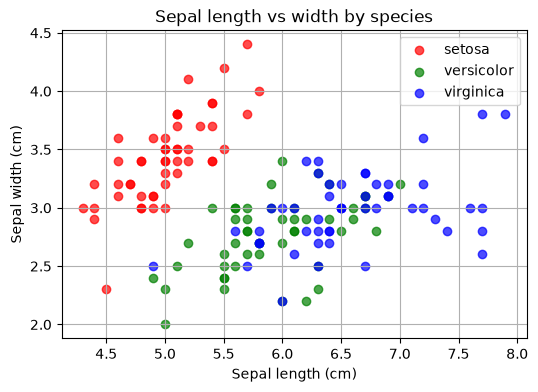

In [204]:
import matplotlib.pyplot as plt

# Scatter: sepal length vs sepal width, color by species
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

plt.figure(figsize=(6, 4))
for species, subset in df.groupby('species'):
    plt.scatter(subset['sepal length (cm)'], subset['sepal width (cm)'],
                label=species, color=colors[species], alpha=0.7)

plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Sepal length vs width by species")
plt.legend()
plt.grid(True)
plt.show()


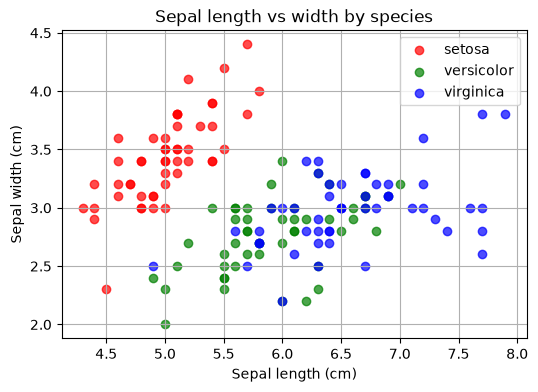

In [205]:
import matplotlib.pyplot as plt

# Scatter: sepal length vs sepal width, color by species
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

plt.figure(figsize=(6, 4))
for species, subset in df.groupby('species'):
    plt.scatter(subset['sepal length (cm)'], subset['sepal width (cm)'],
                label=species, color=colors[species], alpha=0.7)

plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Sepal length vs width by species")
plt.legend()
plt.grid(True)
plt.show()


### Histograms  

Histograms show the distribution of a single feature.  
- `plt.hist` creates bins (intervals) and counts how many samples fall into each.  
- You can control the number of bins with `bins=`.  


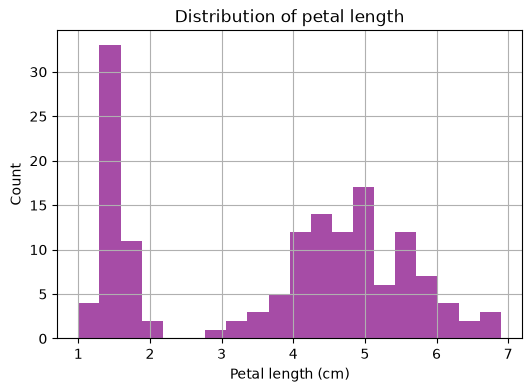

In [206]:
plt.figure(figsize=(6, 4))
plt.hist(df['petal length (cm)'], bins=20, color='purple', alpha=0.7)
plt.xlabel("Petal length (cm)")
plt.ylabel("Count")
plt.title("Distribution of petal length")
plt.grid(True)
plt.show()


### Multiple subplots  

We can place several plots side by side using `plt.subplots`.  
This is useful for comparing different features at once.  


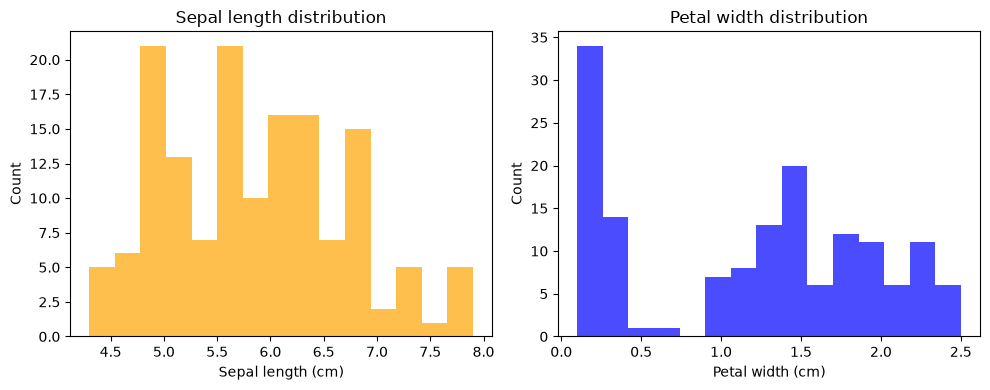

In [207]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Histogram of sepal length
axes[0].hist(df['sepal length (cm)'], bins=15, color='orange', alpha=0.7)
axes[0].set_xlabel("Sepal length (cm)")
axes[0].set_ylabel("Count")
axes[0].set_title("Sepal length distribution")

# Histogram of petal width
axes[1].hist(df['petal width (cm)'], bins=15, color='blue', alpha=0.7)
axes[1].set_xlabel("Petal width (cm)")
axes[1].set_ylabel("Count")
axes[1].set_title("Petal width distribution")

plt.tight_layout()
plt.show()


### Exercises

#### Exercise 1

Use the Iris dataset (`df`) from earlier.
- Make a scatter plot of **petal length vs petal width**.  
- Encode the **species** with different **colors**.   
- Add axis labels, a title, and a legend.  


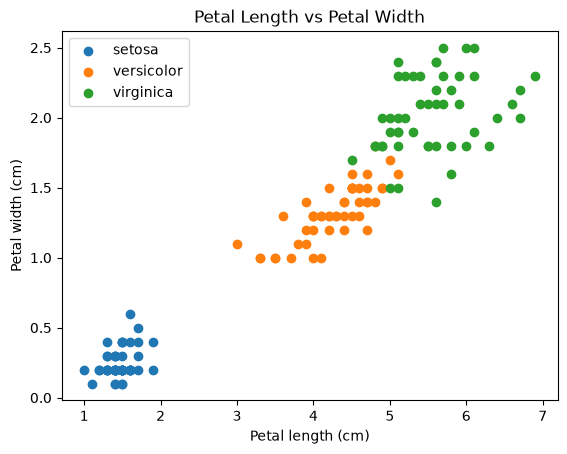

In [208]:


species = df["species"].unique()

for specie in species:
    data = df[df["species"] == specie]
    plt.scatter(
        data["petal length (cm)"],
        data["petal width (cm)"],
        label=specie
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal Length vs Petal Width")
plt.legend()
plt.show()



#### Exercise 2

Using the Iris dataset (`df`):

- Plot histograms of **petal length** for the three species, all in the **same plot**.  
- Use different colors and add a legend.  
- Set the number of bins to 20.  
- Make the plot semi-transparent so the distributions overlap visibly.  



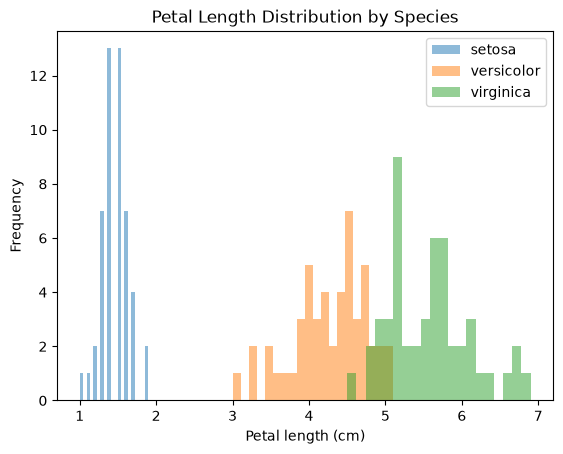

In [209]:
for species in df["species"].unique():
    data = df[df["species"] == species]
    
    plt.hist(
        data["petal length (cm)"],
        bins=20,
        alpha=0.5,
        label=species
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Frequency")
plt.title("Petal Length Distribution by Species")
plt.legend()
plt.show()

#### Exercise 3

Using the Iris dataset (`df`):

- Create a figure with **2 rows and 2 columns of subplots**.  
- In each subplot, plot a histogram for one of the features:
  - Sepal length
  - Sepal width
  - Petal length
  - Petal width
- Add titles to each subplot with the feature name.  
- Adjust the layout so labels don’t overlap (`plt.tight_layout()`).


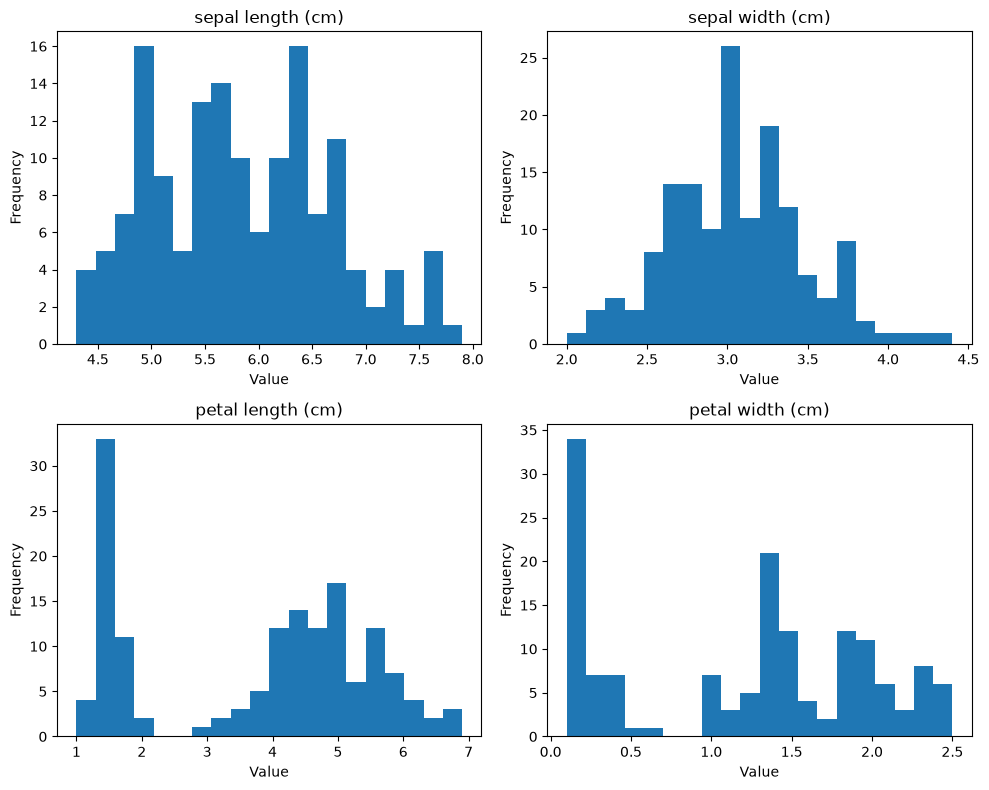

In [210]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

features = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

for ax, feature in zip(axes.ravel(), features):
    ax.hist(df[feature], bins=20)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## First ML model with scikit-learn

### What is scikit-learn?  

[scikit-learn](https://scikit-learn.org/stable/) is one of the most widely used machine learning libraries in Python.  

- Provides **classical ML algorithms** (classification, regression, clustering, dimensionality reduction).  
- Includes **preprocessing tools** (scaling, encoding, feature selection).  
- Designed with a **consistent API** so all models and transformers feel the same.  
- Built on top of NumPy, SciPy, and Matplotlib.  

In this section, we will learn the **scikit-learn API pattern** and train our **first ML model**: k-Nearest Neighbors.  


### The scikit-learn API pattern  

Every object in scikit-learn (model or transformer) follows the same workflow:  

1. **Create the estimator**  
   - Example: `KNeighborsClassifier(n_neighbors=3)`  
   - Hyperparameters are set here.  

2. **Fit to data**  
   - `estimator.fit(X, y)`  
   - Learns parameters from the data (model weights, means/stds, etc.).  

3. **Use the trained object**  
   - **Transformers** (preprocessing):  
     - `transform(X)` → apply transformation.  
     - `fit_transform(X)` → shortcut for `fit` + `transform`.  
   - **Predictors (models)**:  
     - `predict(X)` → output labels.  
     - `predict_proba(X)` → output probabilities (if supported).  
     - `score(X, y)` → quick evaluation (accuracy for classifiers, R² for regressors).  

This unified design makes it easy to switch between algorithms or combine preprocessing + models in a pipeline.  




In [211]:
from sklearn.neighbors import KNeighborsClassifier

X = df.drop(columns=['target', 'species'])
y = df['species']

# Create model (k=3 neighbors)
model = KNeighborsClassifier(n_neighbors=3)


# Fit the model
model.fit(X, y)


# Predict labels for the same data
y_pred = model.predict(X)


# Print the first 5 real labels and first 5 predictions. Compute the score
print("First 5 true labels:", y[:5].values)
print("First 5 predicted labels:", y_pred[:5])
score = np.mean(y_pred == y)
print("Model accuracy on training data (manual):", score)
print("Model accuracy on training data:", model.score(X, y))



First 5 true labels: <StringArray>
['setosa', 'setosa', 'setosa', 'setosa', 'setosa']
Length: 5, dtype: str
First 5 predicted labels: [np.str_('setosa') np.str_('setosa') np.str_('setosa') np.str_('setosa')
 np.str_('setosa')]
Model accuracy on training data (manual): 0.96
Model accuracy on training data: 0.96


### Why scaling matters - StandardScaler

kNN uses **distances** between points.  
- If one feature has much larger values (e.g., cm vs mm), it dominates the distance.  
- Solution: **standardize features** (subtract mean, divide by std).  

scikit-learn provides `StandardScaler` for this.  

`StandardScaler` is a **transformer**.  
It computes the **mean** and **standard deviation** of each feature, and then standardizes:

$$
x' = \frac{x - \mu}{\sigma}
$$

Steps:
1. **fit(X)** → compute means and stds for each column of X.  
   (The values are stored in `scaler.mean_` and `scaler.scale_`.)

2. **transform(X)** → apply the standardization using the stored statistics.  
   (Subtract mean and divide by std for each feature.)

3. **fit_transform(X)** → convenience shortcut that does both in one step.  

Why it matters:
- For distance-based models (like kNN), scaling ensures all features contribute equally.  
- As we will see later on, gradient-based models (like neural networks), scaling makes optimization faster and more stable.  


In [212]:
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['target', 'species'])

scaler = StandardScaler()

# Step 1: fit -> compute mean and std
scaler.fit(X)

print("Means:", scaler.mean_)
print("Standard deviations:", scaler.scale_)

# Step 2: transform -> apply scaling
X_scaled = scaler.transform(X)

print("\nScaled data:")
print(X_scaled)


# Step 3: fit_transform -> same in one call

X_scaled_2 = scaler.fit_transform(X)

print("\nSame result using fit_transform:")
print(X_scaled_2)



Means: [5.84333333 3.05733333 3.758      1.19933333]
Standard deviations: [0.82530129 0.43441097 1.75940407 0.75969263]

Scaled data:
[[-9.00681170e-01  1.01900435e+00 -1.34022653e+00 -1.31544430e+00]
 [-1.14301691e+00 -1.31979479e-01 -1.34022653e+00 -1.31544430e+00]
 [-1.38535265e+00  3.28414053e-01 -1.39706395e+00 -1.31544430e+00]
 [-1.50652052e+00  9.82172869e-02 -1.28338910e+00 -1.31544430e+00]
 [-1.02184904e+00  1.24920112e+00 -1.34022653e+00 -1.31544430e+00]
 [-5.37177559e-01  1.93979142e+00 -1.16971425e+00 -1.05217993e+00]
 [-1.50652052e+00  7.88807586e-01 -1.34022653e+00 -1.18381211e+00]
 [-1.02184904e+00  7.88807586e-01 -1.28338910e+00 -1.31544430e+00]
 [-1.74885626e+00 -3.62176246e-01 -1.34022653e+00 -1.31544430e+00]
 [-1.14301691e+00  9.82172869e-02 -1.28338910e+00 -1.44707648e+00]
 [-5.37177559e-01  1.47939788e+00 -1.28338910e+00 -1.31544430e+00]
 [-1.26418478e+00  7.88807586e-01 -1.22655167e+00 -1.31544430e+00]
 [-1.26418478e+00 -1.31979479e-01 -1.34022653e+00 -1.44707648e

### Pipelines in scikit-learn  

A **Pipeline** chains multiple steps (preprocessing + model) into **one estimator**.  
This makes your workflow cleaner, safer, and less error-prone.  

Why use pipelines?  
- **Keep steps together**: preprocessing and model are trained and applied as one unit.  
- **Avoid mistakes**: no need to remember to scale test data manually.  
- **Consistent API**: the whole pipeline has `.fit()`, `.predict()`, `.score()`.  
- **Easy tuning**: later, we can adjust hyperparameters for *all steps* in one place.  

**How it works**:  
- When you call `pipe.fit(X, y)`:  
  1. Each transformer (e.g. `StandardScaler`) runs `fit` and `transform`.  
  2. The final estimator (e.g. `KNeighborsClassifier`) runs `fit` on the transformed data.  
- When you call `pipe.predict(X)`:  
  1. The transformers run `transform`.  
  2. The final estimator runs `predict`.  

Think of it as a sequence of steps applied in order, with one unified interface.  


In [213]:
from sklearn.pipeline import Pipeline

# Define a pipeline with two steps:
# 1. Scale features
# 2. Run kNN classifier
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])


# Fit the whole pipeline
pipe.fit(X, df["target"])

# Use it like a single model
print("Training accuracy:", pipe.score(X, df["target"]))



Training accuracy: 0.9533333333333334


#### Exercise — Influence of k in kNN 

Use the Iris dataset (`df`) and the `KNeighborsClassifier`.

**Task:**
1. Train kNN classifiers for `k = 1, 3, 5, ..., 25`.  
2. For each value of `k`, compute the **training accuracy**.  
3. Plot the training accuracy as a function of `k`.  

* What happens to the accuracy when `k=1`?  
* And when `k` becomes large?


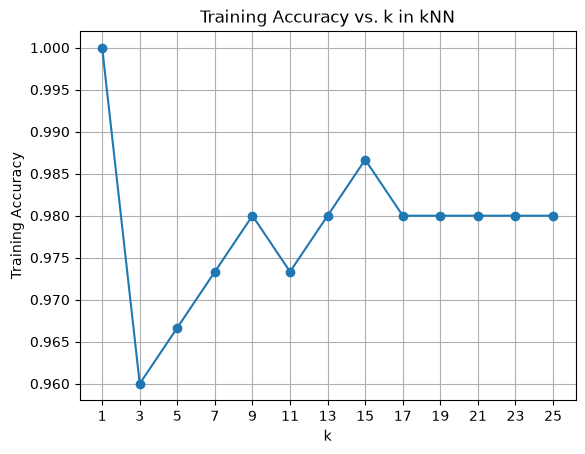

In [214]:
X = df.drop(columns=["target", "species"])
y = df["target"]

k_values = range(1, 26, 2)
train_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X, y)
    
    accuracy = knn.score(X, y)
    train_accuracies.append(accuracy)

plt.plot(k_values, train_accuracies, marker="o")
plt.xlabel("k")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy vs. k in kNN")
plt.xticks(k_values)
plt.grid()
plt.show()

#### Exercise — Visualizing kNN Decision Boundaries

To better understand how kNN works, let’s train using only **two features**:
- Sepal length (cm)
- Sepal width (cm)

**Task:**
1. Select only these two features from the Iris dataset.  
2. Train a kNN classifier with `k=5`.  
3. Create a fine grid over the feature space and predict the class of each point.  
4. Use `plt.contourf` to plot the decision regions.  
5. Overlay the original data points on top, colored by species.


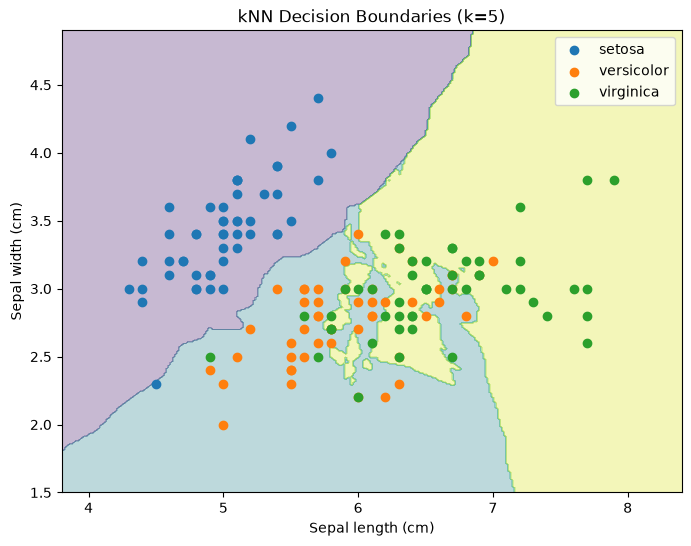

In [218]:
# 1. Select the two features
X = df[["sepal length (cm)", "sepal width (cm)"]]
y = df["target"]

# 2. Train kNN with k=5
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

# 3. Create a fine grid
x_min, x_max = X["sepal length (cm)"].min() - 0.5, X["sepal length (cm)"].max() + 0.5
y_min, y_max = X["sepal width (cm)"].min() - 0.5, X["sepal width (cm)"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Use the same feature names as the training data
grid_df = pd.DataFrame(
    grid,
    columns=["sepal length (cm)", "sepal width (cm)"]
)

# Predict classes
Z = knn.predict(grid_df)
Z = Z.reshape(xx.shape)

# 4. Plot decision regions
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)

# 5. Plot original data
for species in df["species"].unique():
    data = df[df["species"] == species]
    plt.scatter(
        data["sepal length (cm)"],
        data["sepal width (cm)"],
        label=species
    )

plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("kNN Decision Boundaries (k=5)")
plt.legend()
plt.show()

### KNN for Regression

While `KNeighborsClassifier` predicts discrete labels using majority voting, `KNeighborsRegressor` predicts a continuous target variable by calculating the mean (or weighted mean) of the target values of its $k$ nearest neighbors.

#### Exercise - Uniform vs. Distance-Weighted Interpolation

In this exercise, you will visualize how `KNeighborsRegressor` fits a non-linear sinusoidal function and compare uniform voting versus distance-weighted voting (`weights='distance'`).

**Task:**
1. Generate a 1D synthetic dataset with noise:
2. Create a dense grid of test points for smooth plotting:
3. Train two regressors with $k=5$:
    * Model 1: `KNeighborsRegressor(n_neighbors=5, weights='uniform')`
    * Model 2: `KNeighborsRegressor(n_neighbors=5, weights='distance')`
4. Predict outcomes for X_plot using both models.
5. Plot the original noisy training points alongside the prediction curves for both models in a single plot.

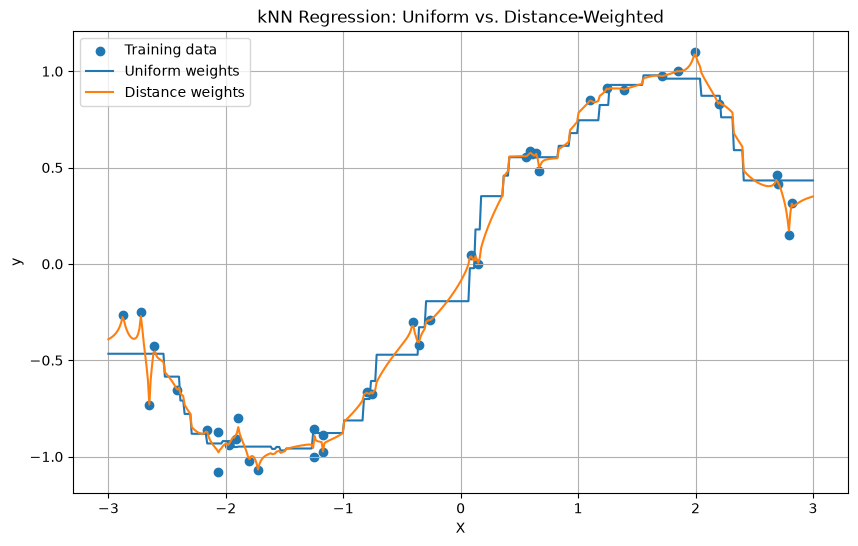

In [220]:
from sklearn.neighbors import KNeighborsRegressor

# 1. Synthetic dataset
np.random.seed(42)
X_train = np.sort(np.random.uniform(-3, 3, size=(40, 1)), axis=0)
y_train = np.sin(X_train).ravel() + np.random.normal(0, 0.1, size=40)

y_train = np.sin(X_train).ravel() + np.random.normal(0, 0.1, size=40)

# 2. Dense grid for smooth plotting
X_plot = np.linspace(-3, 3, 500).reshape(-1, 1)

# 3. Train two kNN regressors with k=5
knn_uniform = KNeighborsRegressor(
    n_neighbors=5,
    weights="uniform"
)

knn_distance = KNeighborsRegressor(
    n_neighbors=5,
    weights="distance"
)

knn_uniform.fit(X_train, y_train)
knn_distance.fit(X_train, y_train)

# 4. Predict on the grid
y_pred_uniform = knn_uniform.predict(X_plot)
y_pred_distance = knn_distance.predict(X_plot)

# 5. Plot
plt.figure(figsize=(10, 6))

plt.scatter(
    X_train,
    y_train,
    label="Training data"
)

plt.plot(
    X_plot,
    y_pred_uniform,
    label="Uniform weights"
)

plt.plot(
    X_plot,
    y_pred_distance,
    label="Distance weights"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("kNN Regression: Uniform vs. Distance-Weighted")
plt.legend()
plt.grid()
plt.show()